# EELS versus Best Cost: persistent TT (protocol 3)

This report analyzes `data/eels_optimization/gamma1_persistent_v3/` only.
It does not combine these data with the old reset/rebuild EELS or SA results.
There are 250 paired assignment tasks per objective: n = 12, 13, 14, 15, 16,
with 50 instances per size, and n squared binary variables. Objectives come
from the existing `test_random_vectors` and `test_random_bilinear_forms` files.
No hyperparameter selection is performed on these results.

## Saved protocol

Both arms receive the same 400 initial feasible draws. Each TT is constructed
**once**, orthogonalized and normalized. Best Cost uses Method (ii); the other
arm applies EELS with gamma = 1 **once at initialization**. Learned amplitudes
are then retained, and the structural support is fixed throughout optimization.

Each of 20 iterations first samples 10,000 points with the legacy backend,
deduplicates them, and trains on at most the best 400 distinct points **from
that new batch only**. Neither the initial data nor old elites are injected
into later training batches. The best-ever solution is recorded separately.
There are no restarts, no subsequent TT reinitializations and no external draws.
The first sampling round precedes the first training sweep.

Training uses one sweep, learning rate 0.05, nondegenerate charge blocks, and
normalized Boltzmann weights with temperature equal to the standard deviation
of the current elite costs. The stored UTILITY_FRACTION = 0.05 controls a logged
utility statistic; it does **not** reduce the training set to 20 points.
Iteration sampling seeds are paired; identical seeds do not imply identical
samples from different trained distributions.

## A/B procedure

As in the earlier reports, use a one-sided paired Wilcoxon signed-rank test on
raw costs, alternative `Best Cost - EELS > 0`. Display raw p-values plus Holm
adjustment for the two primary objective-level tests. The ten size-specific
tests are supplementary and receive their own Holm correction. The test does
not specifically test the mean percentage gain; its location interpretation
uses the usual symmetry assumption for paired differences.

Improvement is `100 * (Best Cost - EELS) / abs(Best Cost)`; positive values favor
EELS. Pooling all sizes follows the earlier analysis; separate size tables
are included because raw difference magnitudes can vary with size. One seed is
used per task. This compares equal sample/iteration settings, not equal time.


In [1]:
from pathlib import Path
import csv, html
from IPython.display import display, HTML, Markdown, Image
root = Path.cwd()
if not (root / "Project.toml").exists(): root = root.parent
out = root / "examples" / "eels_persistent_analysis"
def read(name):
    with (out / name).open(encoding="utf-8") as f: return list(csv.DictReader(f))
def table(headers, rows):
    display(HTML('<table><thead><tr>' + ''.join('<th>'+html.escape(str(x))+'</th>' for x in headers) + '</tr></thead><tbody>' + ''.join('<tr>'+''.join('<td>'+html.escape(str(x))+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>'))
def pct(x): return f"{float(x):.1f}%"
def pv(x): return f"{float(x):.3g}"
summary, groups, pairs = read('summary.csv'), read('by_size.csv'), read('paired_costs.csv')
display(Markdown((out/'audit.md').read_text(encoding='utf-8')))
table(['Objective','Pairs','Mean improvement','Median improvement','Wins / ties / losses','Raw p','Holm p (2)'],
      [[r['objective'], r['N'], pct(r['mean_relative']), pct(r['median_relative']),
        f"{r['wins']} / {r['ties']} / {r['losses']}", pv(r['p']), pv(r['p_holm2'])] for r in summary])

Validated 500 paired tasks / 1,000 runs. Both protocol-3 files are complete. All objective-file hashes match; all final solutions are binary, feasible, and have the stored cost. Initial samples were regenerated from the saved seed rule, sorted as in the runner, and matched both training-data fingerprints exactly. Histories are monotone; each arm records exactly one initialization and 20 iterations; EELS is applied only once in the enhanced arm. Training sizes never exceed 400. No external samples are injected.

linear: 250 complete pairs; SHA256 84f0d63f56c49cc7da84c682bb062dbeb63c4ea3e92ed2b7d6fd2ffda8110017; Julia 1.12.5.

quadratic: 250 complete pairs; SHA256 b2b51c8a4cd44cf16dafe4b43bbde8cdc8f136e46b7625bfa783c317a4f49482; Julia 1.12.5.



Objective,Pairs,Mean improvement,Median improvement,Wins / ties / losses,Raw p,Holm p (2)
linear,250,3.1%,0.0%,125 / 116 / 9,1.97e-19,3.94e-19
quadratic,250,3.1%,0.2%,128 / 100 / 22,1.39e-15,1.39e-15


## Relative improvement by size

Exactly two boxplots are shown, one per objective, with identical y limits.
Each box contains all 50 paired tasks of that size. Whiskers extend to the
furthest observations within 1.5 IQR; outliers are shown. The two overlays are
the group average and group median of those same 50 observations. All displayed
percentages use one decimal place; exported CSV values retain full precision.


### Linear assignment

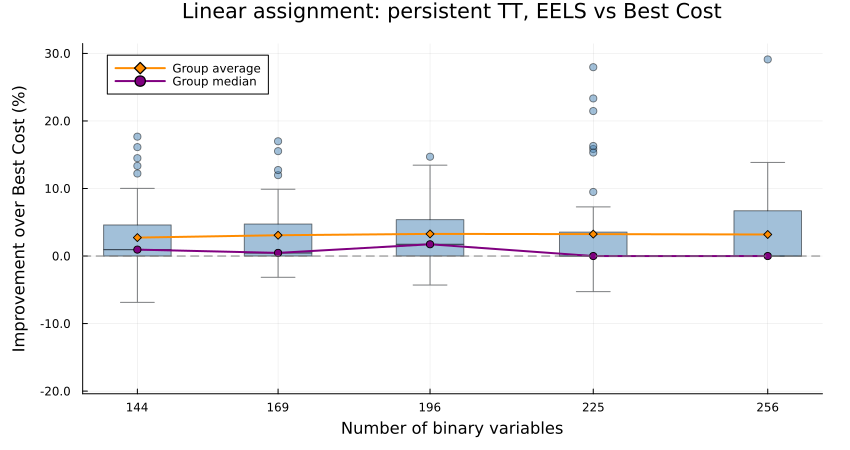

n,Variables,Pairs,Mean improvement,Median improvement,Wins / ties / losses,Raw p,Holm p (10)
12,144,50,2.7%,1.0%,30 / 15 / 5,4.22e-05,0.000211
13,169,50,3.1%,0.5%,27 / 22 / 1,3.28e-07,2.95e-06
14,196,50,3.3%,1.7%,30 / 18 / 2,3.45e-07,2.95e-06
15,225,50,3.2%,0.0%,17 / 32 / 1,9.54e-05,0.000381
16,256,50,3.2%,0.0%,21 / 29 / 0,4.77e-07,3.34e-06


In [2]:
display(Image(filename=str(out/'EELS_linear.png')))
table(['n','Variables','Pairs','Mean improvement','Median improvement','Wins / ties / losses','Raw p','Holm p (10)'],
      [[r['n'], r['variables'], r['N'], pct(r['mean_relative']), pct(r['median_relative']),
        f"{r['wins']} / {r['ties']} / {r['losses']}", pv(r['p']), pv(r['p_holm10'])]
       for r in groups if r['objective']=='linear'])

### Quadratic assignment

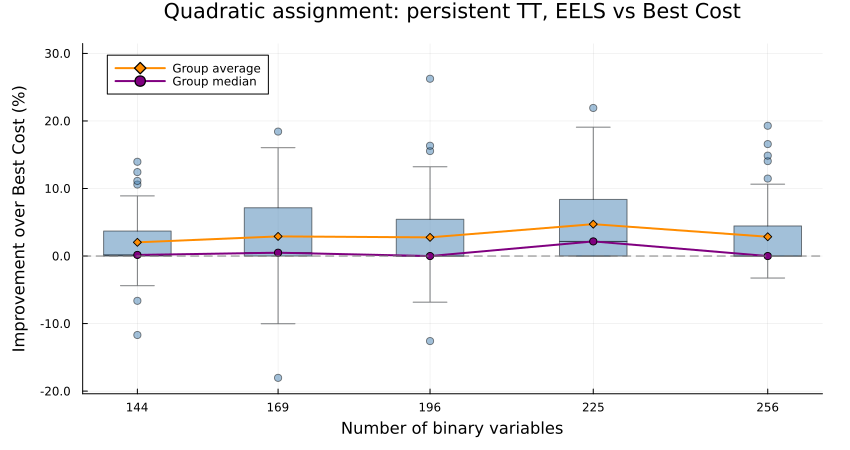

n,Variables,Pairs,Mean improvement,Median improvement,Wins / ties / losses,Raw p,Holm p (10)
12,144,50,2.0%,0.2%,26 / 17 / 7,0.000686,0.00206
13,169,50,2.9%,0.5%,28 / 14 / 8,0.00117,0.00206
14,196,50,2.8%,0.0%,22 / 22 / 6,0.00102,0.00206
15,225,50,4.7%,2.2%,30 / 20 / 0,9.31e-10,9.31e-09
16,256,50,2.9%,0.0%,22 / 27 / 1,3.93e-06,2.36e-05


In [3]:
display(Image(filename=str(out/'EELS_quadratic.png')))
table(['n','Variables','Pairs','Mean improvement','Median improvement','Wins / ties / losses','Raw p','Holm p (10)'],
      [[r['n'], r['variables'], r['N'], pct(r['mean_relative']), pct(r['median_relative']),
        f"{r['wins']} / {r['ties']} / {r['losses']}", pv(r['p']), pv(r['p_holm10'])]
       for r in groups if r['objective']=='quadratic'])

## Interpretation and scope

The following statements are generated from the stored paired results, without
choosing favorable sizes or deleting ties. A significant improvement supports
the value of the one-time EELS enhancement **within this persistent-TT protocol**.
It does not establish superiority over SA, which used a different protocol and
budgets, nor a speed advantage over Best Cost.


In [4]:
for r in summary:
    significant = float(r['p_holm2']) < .05
    direction = "improves" if float(r['mean_relative']) > 0 else "does not improve"
    display(Markdown(f"**{r['objective'].title()}:** EELS {direction} the mean relative objective: {pct(r['mean_relative'])}; median {pct(r['median_relative'])}. "
                     f"There are {r['wins']} wins, {r['ties']} ties, and {r['losses']} losses out of {r['N']} tasks. "
                     f"The one-sided advantage {'passes' if significant else 'does not pass'} the two-test Holm correction (p = {pv(r['p_holm2'])})."))
table(['Objective','n','Mean structural support ratio: EELS / baseline','Mean distinct evaluations: baseline / EELS'],
      [[o,n,f"{sum(float(r['eels_support'])/float(r['baseline_support']) for r in pairs if r['objective']==o and int(r['n'])==n)/50:.2f}",
        ' / '.join(f"{sum(float(r[k]) for r in pairs if r['objective']==o and int(r['n'])==n)/50:,.0f}" for k in ['baseline_unique_evaluations','eels_unique_evaluations'])]
       for o in ['linear','quadratic'] for n in range(12,17)])

**Linear:** EELS improves the mean relative objective: 3.1%; median 0.0%. There are 125 wins, 116 ties, and 9 losses out of 250 tasks. The one-sided advantage passes the two-test Holm correction (p = 3.94e-19).

**Quadratic:** EELS improves the mean relative objective: 3.1%; median 0.2%. There are 128 wins, 100 ties, and 22 losses out of 250 tasks. The one-sided advantage passes the two-test Holm correction (p = 1.39e-15).

Objective,n,Mean structural support ratio: EELS / baseline,Mean distinct evaluations: baseline / EELS
linear,12,2.22,"13,633 / 14,672"
linear,13,2.19,"12,801 / 13,924"
linear,14,2.05,"11,773 / 12,868"
linear,15,1.84,"10,687 / 11,753"
linear,16,1.71,"9,465 / 10,624"
quadratic,12,2.25,"15,108 / 16,525"
quadratic,13,2.17,"14,049 / 15,381"
quadratic,14,2.03,"12,589 / 13,937"
quadratic,15,1.85,"11,278 / 12,561"
quadratic,16,1.69,"9,745 / 11,038"


Here the evaluation diagnostic is the number of **distinct cached points**,
not total invocations as in the SA report. It must not be compared directly to
the SA objective-call counts. Support refers to the initial structural indicator,
not the norm of a trained probability distribution. Saved concurrent elapsed
times are not isolated single-core speed measurements.

## Reproduction

```text
julia --project=. --threads=1,0 scripts/report_EELS_persistent.jl
python scripts/build_EELS_persistent_notebook.py --execute
```

These commands audit saved outputs and regenerate the report without running
optimization. The audit reproduces the initial training samples from seeds and
checks their fingerprints, all input hashes, final feasibility/costs, recorded
single initialization, and bounded batch-only training sizes. Figures are
generated with Julia; tables render as HTML. The manuscript is unchanged.
